
Student number: 193551
Group: CNS 3B
# Wi-Fi deauthentication attack detector (WIDS)
A Random Forest that labels each one-second window of Wi-Fi traffic as **normal** or **deauth attack**.

The original capture is too big to share, so this notebook loads `data/windows.csv` from the GitHub repo: the same
capture already turned into one row per second (see `src/features.py`). The same model is trained three ways,
from easiest to hardest:

| Setup | What the model can see |
|---|---|
| All features | includes the deauth counters (nearly gives away the label) |
| No deauth counters | flood only shows in total traffic rate and signal |
| Deauth frames hidden | only side effects on the other traffic (hardest) |



In [1]:
# download the repo from GitHub and find the data file
import glob, os, subprocess

REPO = "https://github.com/deeyarajgor/ML_based_WIDS-WIPS.git"
FOLDER = "wids"

if not os.path.exists(FOLDER):
    subprocess.run(["git", "clone", REPO, FOLDER], check=True)

hits = glob.glob(f"{FOLDER}/**/windows.csv", recursive=True)
if not hits:
    print("windows.csv not found. Files in the repo:")
    for f in sorted(glob.glob(f"{FOLDER}/**/*", recursive=True)):
        if ".git/" not in f:
            print("  ", f)
    raise FileNotFoundError("data/windows.csv is not in the repo - run src/export_windows.py, "
                            "then git add, commit and push it.")
DATA_FILE = hits[0]
print("Using", DATA_FILE)

Using wids/data/windows.csv


In [2]:
# load the windows and split by time (first 70% train, last 30% test)
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)

# the same feature lists as src/features.py
FEATURE_COLUMNS = ["frames_per_sec", "deauth_count", "deauth_ratio",
                   "mgmt_count", "rssi_mean", "rssi_std", "subtype_variety"]
FEATURE_COLUMNS_BLIND = ["frames_per_sec", "mgmt_count_nd", "rssi_mean",
                         "rssi_std", "subtype_variety_nd"]
FEATURE_COLUMNS_STRICT = ["frames_per_sec_nd", "mgmt_count_nd", "rssi_mean_nd",
                          "rssi_std_nd", "subtype_variety_nd"]
TEST_FRACTION = 0.3

windows = pd.read_csv(DATA_FILE).sort_values("window").reset_index(drop=True)
needed = set(FEATURE_COLUMNS + FEATURE_COLUMNS_BLIND + FEATURE_COLUMNS_STRICT + ["label", "window"])
missing = needed - set(windows.columns)
assert not missing, f"windows.csv is missing columns {missing} - re-run src/export_windows.py and push"

cut = int(len(windows) * (1 - TEST_FRACTION))
train, test = windows.iloc[:cut], windows.iloc[cut:]
print(f"{len(windows)} windows -> train {len(train)}, test {len(test)} "
      f"({int(test['label'].sum())} attack, {int((test['label'] == 0).sum())} normal)")

917 windows -> train 641, test 276 (97 attack, 179 normal)


In [3]:
# train one model per setup and score it on the test period
SETS = {"All features": FEATURE_COLUMNS,
        "No deauth counters": FEATURE_COLUMNS_BLIND,
        "Deauth frames hidden": FEATURE_COLUMNS_STRICT}

truth = test["label"]
preds, rows = {}, []
for name, cols in SETS.items():
    model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
    model.fit(train[cols], train["label"])
    preds[name] = model.predict(test[cols])
    rows.append({"setup": name,
                 "accuracy": accuracy_score(truth, preds[name]),
                 "precision": precision_score(truth, preds[name], zero_division=0),
                 "recall": recall_score(truth, preds[name], zero_division=0),
                 "f1": f1_score(truth, preds[name], zero_division=0)})

results = pd.DataFrame(rows).set_index("setup")
results.style.format("{:.1%}")

,accuracy,precision,recall,f1
setup,,,,
All features,100.0%,100.0%,100.0%,100.0%
No deauth counters,98.6%,97.0%,99.0%,98.0%
Deauth frames hidden,66.7%,51.7%,80.4%,62.9%


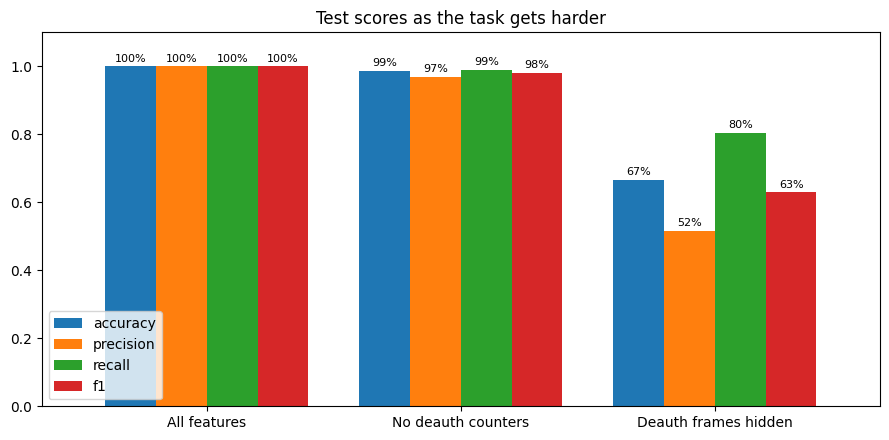

In [4]:
# graph: scores for each setup
ax = results.plot.bar(figsize=(9, 4.5), rot=0, ylim=(0, 1.1), width=0.8)
ax.set_title("Test scores as the task gets harder")
ax.set_xlabel("")
ax.legend(loc="lower left")
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{b.get_height():.0%}" for b in bars], fontsize=8, padding=2)
plt.tight_layout()
plt.show()

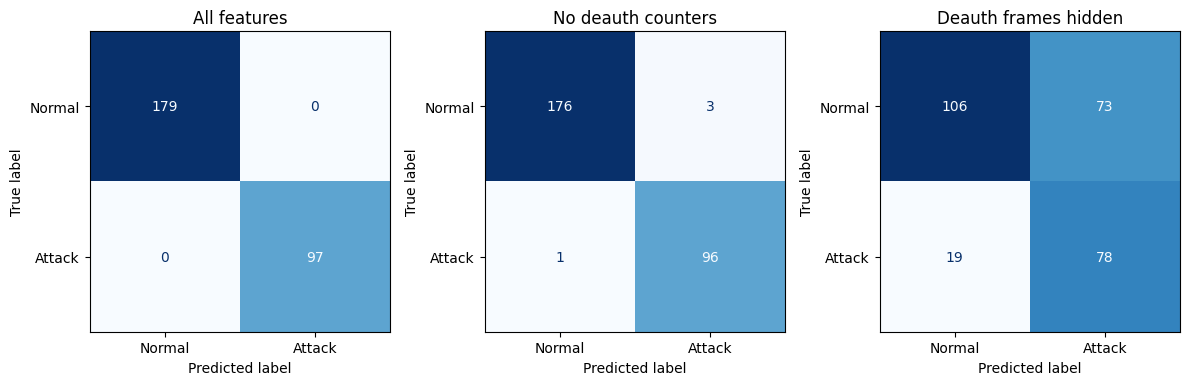

In [5]:
# confusion matrices (rows = real, columns = predicted)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(truth, pred, labels=[0, 1]),
                           display_labels=["Normal", "Attack"]).plot(
        ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

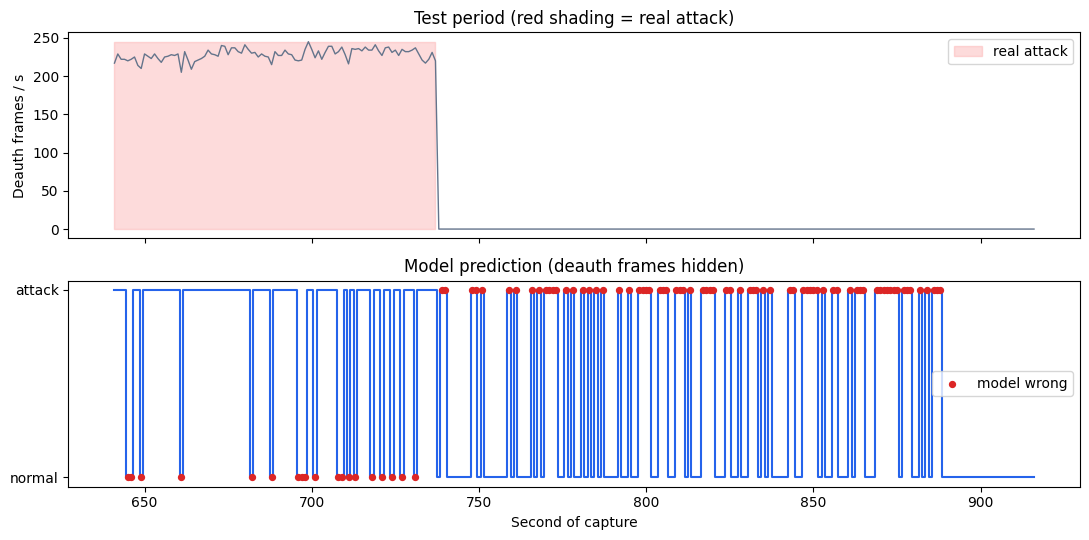

In [6]:
# the hardest model over time: where it was right and where it was wrong
pred = preds["Deauth frames hidden"]
t = test["window"].to_numpy()
real = truth.to_numpy()
wrong = pred != real

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
top.plot(t, test["deauth_count"], color="#64748B", linewidth=1)
top.fill_between(t, 0, max(test["deauth_count"].max(), 1), where=real == 1,
                 color="#FCA5A5", alpha=0.4, label="real attack")
top.set_ylabel("Deauth frames / s")
top.set_title("Test period (red shading = real attack)")
top.legend(loc="upper right")

bottom.step(t, pred, where="mid", color="#2563EB")
bottom.scatter(t[wrong], pred[wrong], color="#DC2626", s=18, zorder=3, label="model wrong")
bottom.set_yticks([0, 1])
bottom.set_yticklabels(["normal", "attack"])
bottom.set_xlabel("Second of capture")
bottom.set_title("Model prediction (deauth frames hidden)")
bottom.legend(loc="center right")
plt.tight_layout()
plt.show()

In [7]:
import sklearn
print(sklearn.__version__)

1.6.1
